1. What is NER?
* NER (Named Entity Recognition is an NLP Technique used to identify and classify named entities in text)

In [ ]:
# Install spacy
!pip install spacy

In [ ]:
# Download the English Model:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 22.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# 1: basic NER

import spacy
nlp = spacy.load("en_core_web_sm")
text="Apple is headdquartered in California."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

Apple ORG
California GPE


In [ ]:
# 2: Porson Indentification

text="Elon Musk is the CEO of Tesla."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

Elon Musk PERSON
Tesla ORG


In [ ]:
# 3: Organization

text="Google and Micorsoft headdquartered in California."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

Micorsoft GPE
California GPE


In [ ]:
# 4: Location

text="India is located in South Asia."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

India GPE
South Asia LOC


In [ ]:
# 5: Dates

text="The conference will be help on 15 September 2026."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

15 September 2026 DATE


In [ ]:
# 6: Money

text="The money is $1000."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

1000 MONEY


In [ ]:
#7 Percentage
text= "The percentage is 50%."
doc=nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

50% PERCENT


In [ ]:
#8 Extract Only person Entity
text = """
Sundar Pichai is the CEO of google.
Satya Nadella is the CEO of Microsoft.
"""
doc=nlp(text)
for ent in doc.ents:
  if ent.label_=="PERSON":
    print(ent.text,ent.label_)

Sundar Pichai PERSON
Satya Nadella PERSON


In [ ]:
#9 Extract Organizations
text = """
Google developed several AI products.
Microsoft also invests heavily in artificial intelligence.
"""
doc=nlp(text)
for ent in doc.ents:
  if ent.label_=="ORG":
    print(ent.text,ent.label_)

Google ORG
AI ORG
Microsoft ORG


In [ ]:
#10 Extract all entity types
text = """
Ratan Tata visited London on 10 January 2025.
He donated ₹50 crore to a charitable organization.
"""
doc=nlp(text)
for ent in doc.ents:
  print(
      "Entity:",ent.text,
      "|Label:",ent.label_,
      "|Meaning:",spacy.explain(ent.label_)
  )

Entity: Ratan Tata |Label: ORG |Meaning: Companies, agencies, institutions, etc.
Entity: London |Label: GPE |Meaning: Countries, cities, states
Entity: 10 January 2025 |Label: DATE |Meaning: Absolute or relative dates or periods
Entity: 50 |Label: MONEY |Meaning: Monetary values, including unit


In [ ]:
#11 NER Visualization with DisplaCy
text = "Sundar Pichai is the CEO of Google in California."
doc=nlp(text)
spacy.displacy.render(doc,style="ent",jupyter=True)

Counter({'PERSON': 4, 'ORG': 3, 'GPE': 1})


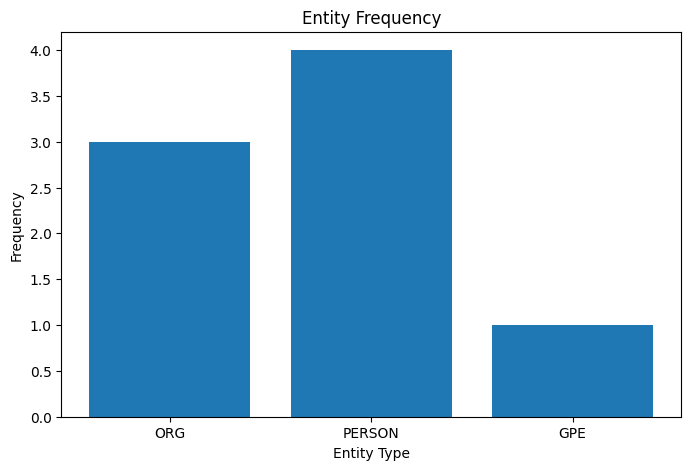

In [ ]:
#13 NER Frequency Visualization
from collections import Counter
import matplotlib.pyplot as plt

text= """
Google was founded by Larry Page and Sergey Brin.
Microsoft was founded by Bill Gates.
Apple was founded by Bill Jobs.
These companies are based in the United States.
"""
doc=nlp(text)
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)
print(entity_counts)
plt.figure(figsize=(8,5))
plt.bar(entity_counts.keys(),entity_counts.values())
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title("Entity Frequency")
plt.show()

In [ ]:
#14 Create an NER DataFrame
import pandas as pd
text = """
Elon Musk founded SpaceX.
Sundar Pichai leads Google.
Satya Nadella founded Microsoft.
"""
doc=nlp(text)
data=[]
for ent in doc.ents:
  data.append({
      "Entity": ent.text,
      "Label":ent.label_,
      "Description":spacy.explain(ent.label_)
  })
df=pd.DataFrame(data)
print(df)

          Entity   Label                              Description
0      Elon Musk  PERSON              People, including fictional
1  Sundar Pichai  PERSON              People, including fictional
2         Google     ORG  Companies, agencies, institutions, etc.
3  Satya Nadella  PERSON              People, including fictional
4      Microsoft     ORG  Companies, agencies, institutions, etc.


Named Entities:
----------------------------------------
Sundar Pichai       PERSON         People, including fictional
Google              ORG            Companies, agencies, institutions, etc.
California          GPE            Countries, cities, states
Satya Nadella       PERSON         People, including fictional
microsoft           ORG            Companies, agencies, institutions, etc.
Elon Musk           PERSON         People, including fictional
Google              ORG            Companies, agencies, institutions, etc.
Microsoft           ORG            Companies, agencies, institutions, etc.
the United States   GPE            Countries, cities, states

Entity Frequency:
Counter({'ORG': 4, 'PERSON': 3, 'GPE': 2})


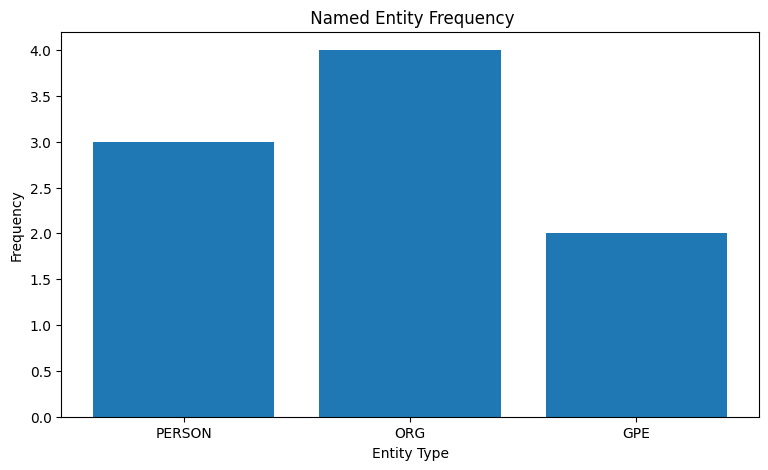

In [ ]:
#15 Complete NER program Visualization
# This combines NER extraction + frequency analysis + visualization + displaCy :
from spacy import displacy
text = """
Sundar Pichai is the CEO of Google in California.
Satya Nadella is the CEO of microsoft.
Elon Musk founded SpaceX.
Google and Microsoft are based in the United States.
"""
#process text
doc=nlp(text)
#display entities
print("Named Entities:")
print("-"*40)

for ent in doc.ents:
  print(
      f"{ent.text:20}"
      f"{ent.label_:15}"
      f"{spacy.explain(ent.label_)}"
  )

#count entity types
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)
print("\nEntity Frequency:")
print(entity_counts)
# Bar chart
plt.figure(figsize=(9,5))

plt.bar(
    entity_counts.keys(),
    entity_counts.values()
)
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.title(" Named Entity Frequency")
plt.show()

# Entity visualization
displacy.render(
    doc,
    style="ent",
    jupyter=True
)